# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [4]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [13]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,longitud_territorial,latitud_territorial,estado_union_inicial,estado_union,procedencia_enlace,fuente_suelo,catalogo_territorial
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,52835,NARIÑO,SAN ANDRÉS DE TUMACO,-78.764073,1.807399,coincidencia_nombre,coincidencia_nombre,nombre_normalizado,agrosavia.csv,DIVIPOLA 2024
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,41676,HUILA,SANTA MARÍA,-75.586223,2.939603,coincidencia_nombre,coincidencia_nombre,nombre_normalizado,agrosavia.csv,DIVIPOLA 2024
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincidencia_nombre,coincidencia_nombre,nombre_normalizado,agrosavia.csv,DIVIPOLA 2024
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincidencia_nombre,coincidencia_nombre,nombre_normalizado,agrosavia.csv,DIVIPOLA 2024
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincidencia_nombre,coincidencia_nombre,nombre_normalizado,agrosavia.csv,DIVIPOLA 2024


(92738, 52)
id_fila                                        Int64
Secuencial                            string[python]
Fecha de Análisis                     string[python]
Departamento                          string[python]
Municipio                             string[python]
Cultivo                               string[python]
Estado                                string[python]
Tiempo de establecimiento             string[python]
Topografia                            string[python]
Drenaje                               string[python]
Riego                                 string[python]
Fertilizantes aplicados               string[python]
pH agua:suelo                         string[python]
Materia organica                      string[python]
Fósforo Bray II                       string[python]
Azufre Fosfato monocalcico            string[python]
Acidez Intercambiable                 string[python]
Aluminio intercambiable               string[python]
Calcio intercambiable             

In [5]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 52)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ id_fila ┆ Secuencial ┆ Fecha de  ┆ Departame ┆ … ┆ estado_un ┆ procedenc ┆ fuente_su ┆ catalogo_ │
│ ---     ┆ ---        ┆ Análisis  ┆ nto       ┆   ┆ ion       ┆ ia_enlace ┆ elo       ┆ territori │
│ i64     ┆ str        ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ al        │
│         ┆            ┆ str       ┆ str       ┆   ┆ str       ┆ str       ┆ str       ┆ ---       │
│         ┆            ┆           ┆           ┆   ┆           ┆           ┆           ┆ str       │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ 1          ┆ 7/01/2014 ┆ NARIÑO    ┆ … ┆ coinciden ┆ nombre_no ┆ agrosavia ┆ DIVIPOLA  │
│         ┆            ┆           ┆           ┆   ┆ cia_nombr ┆ rmalizado ┆ .csv      ┆ 2024      │
│         ┆            ┆           ┆           ┆   ┆ e         ┆           ┆

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [14]:
# Desarrollo
import numpy as np 

COLS = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]
TIPOS_PD = {"id_fila": "Int64", "anio": "Int64", "codigo_departamento": "string",
            "codigo_municipio": "string", "ph": "float64", "ph_valido": "bool"}
ESQUEMA_PL = {"id_fila": pl.Int64, "anio": pl.Int64, "codigo_departamento": pl.String,
              "codigo_municipio": pl.String, "ph": pl.Float64, "ph_valido": pl.Boolean}

# Bitácora de controles de equivalencia
controles = []
def registrar_control(seccion, control, ok, detalle=""):
    controles.append({"seccion": seccion, "control": control, "resultado": "OK" if ok else "FALLA", "detalle": str(detalle)})
    assert ok, f"{control}: {detalle}"

# Proyección común: mismas columnas, mismas filas, tipos equivalentes
assert datos_pd["ph_valido"].notna().all()
proyeccion_pd = datos_pd[COLS].astype(TIPOS_PD)
proyeccion_pl = datos_pl.select([pl.col(c).cast(t) for c, t in ESQUEMA_PL.items()])
print("pandas:", proyeccion_pd.shape); display(proyeccion_pd.dtypes.astype(str).to_frame("pandas").T)
print("Polars:", proyeccion_pl.shape, proyeccion_pl.schema)
registrar_control(1, "filas proyectadas iguales a la entrada", len(proyeccion_pd) == len(datos_pd) == proyeccion_pl.height,
                  f"{len(proyeccion_pd)} / {proyeccion_pl.height}")
registrar_control(1, "id_fila único", proyeccion_pd["id_fila"].is_unique and proyeccion_pl["id_fila"].n_unique() == proyeccion_pl.height)
nulos_pd = proyeccion_pd.isna().sum()
nulos_pl = pd.Series(proyeccion_pl.null_count().row(0), index=COLS)
display(pd.DataFrame({"nulos_pandas": nulos_pd, "nulos_polars": nulos_pl}))
registrar_control(1, "nulos por columna iguales en ambos motores", nulos_pd.equals(nulos_pl), nulos_pd.to_dict())

# Año y departamento elegidos
ANIO, DEPTO = 2016, "25"
presentes = proyeccion_pd["anio"].eq(ANIO).fillna(False).astype(bool) & proyeccion_pd["codigo_departamento"].eq(DEPTO).fillna(False).astype(bool)
print(f"Registros con anio={ANIO} y departamento={DEPTO}:", int(presentes.sum()))
assert presentes.any(), "Elige un año y departamento presentes en los datos"

# Consulta: implementación visible en ambos motores
def consulta_pd(tabla):
    mascara = (tabla["anio"].eq(ANIO).fillna(False).astype(bool)
               & tabla["codigo_departamento"].eq(DEPTO).fillna(False).astype(bool))
    seleccion = tabla.loc[mascara]
    resultado = (seleccion.assign(ph_para_media=seleccion["ph"].where(seleccion["ph_valido"]))
                 .groupby("codigo_municipio", dropna=False, sort=True)
                 .agg(total_analisis=("id_fila", "size"),
                      ph_validos=("ph_valido", "sum"),
                      media_ph_valido=("ph_para_media", "mean"))
                 .reset_index())
    return resultado.astype({"total_analisis": "Int64", "ph_validos": "Int64"})

def consulta_pl(tabla):
    
    # Una comparación con null produce null y filter lo descarta (equivale a fillna(False) en pandas)
    return (tabla.filter((pl.col("anio") == ANIO) & (pl.col("codigo_departamento") == DEPTO))
            .group_by("codigo_municipio")      # group_by conserva la clave null como un grupo
            .agg(pl.len().cast(pl.Int64).alias("total_analisis"),
                 pl.col("ph_valido").sum().cast(pl.Int64).alias("ph_validos"),
                 pl.col("ph").filter(pl.col("ph_valido")).mean().alias("media_ph_valido"))
            .sort("codigo_municipio", nulls_last=True))

# Comparación de resultados (claves, conteos, nulos y medias con tolerancia)
def comparar_resultados(a, b, etiqueta, seccion):
    a = a.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
    b = b.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
    ok_filas = len(a) == len(b)
    ok_claves = ok_filas and a["codigo_municipio"].isna().tolist() == b["codigo_municipio"].isna().tolist() and \
        a["codigo_municipio"].dropna().astype(str).tolist() == b["codigo_municipio"].dropna().astype(str).tolist()
    ok_conteos = ok_filas and all((a[c].astype("Int64").to_numpy() == b[c].astype("Int64").to_numpy()).all()
                                  for c in ["total_analisis", "ph_validos"])
    ok_nulos = ok_filas and a["media_ph_valido"].isna().tolist() == b["media_ph_valido"].isna().tolist()
    ma, mb = a["media_ph_valido"].astype("float64").to_numpy(), b["media_ph_valido"].astype("float64").to_numpy()
    ok_medias = ok_filas and bool(np.isclose(ma, mb, rtol=0, atol=1e-6, equal_nan=True).all())
    dif_max = float(np.nanmax(np.abs(ma - mb))) if ok_filas and len(a) and not np.isnan(ma - mb).all() else 0.0
    registrar_control(seccion, f"{etiqueta}: claves y nulos de clave", ok_claves, f"{len(a)} grupos")
    registrar_control(seccion, f"{etiqueta}: conteos exactos", ok_conteos)
    registrar_control(seccion, f"{etiqueta}: posiciones de media ausente", ok_nulos)
    registrar_control(seccion, f"{etiqueta}: medias atol=1e-6 rtol=0", ok_medias, f"diferencia máxima {dif_max:.2e}")
    return dif_max

resultado_pd = consulta_pd(proyeccion_pd)
resultado_pl = consulta_pl(proyeccion_pl)
display(resultado_pd.head(10))
print(resultado_pl.head(10))
comparar_resultados(resultado_pd, resultado_pl.to_pandas(), "consulta pandas vs Polars", 1)

# Tratamiento de claves nulas: el mismo grupo ausente en ambos motores (tabla completa)
nulo_pd = int(proyeccion_pd.groupby("codigo_municipio", dropna=False).size().loc[lambda s: s.index.isna()].sum())
nulo_pl = proyeccion_pl.group_by("codigo_municipio").len().filter(pl.col("codigo_municipio").is_null())["len"].sum()
print("Filas en el grupo municipal ausente – pandas dropna=False:", nulo_pd, "| Polars group_by:", nulo_pl)
registrar_control(1, "grupo de clave nula equivalente", nulo_pd == nulo_pl, nulo_pd)
print("Grupo municipal ausente en la consulta elegida:", bool(resultado_pd["codigo_municipio"].isna().any()))

pandas: (92738, 6)


,id_fila,anio,codigo_departamento,codigo_municipio,ph,ph_valido
pandas,Int64,Int64,string,string,float64,bool


Polars: (92738, 6) Schema({'id_fila': Int64, 'anio': Int64, 'codigo_departamento': String, 'codigo_municipio': String, 'ph': Float64, 'ph_valido': Boolean})


,nulos_pandas,nulos_polars
id_fila,0,0
anio,0,0
codigo_departamento,1339,1339
codigo_municipio,1339,1339
ph,11,11
ph_valido,0,0


Registros con anio=2016 y departamento=25: 2609


,codigo_municipio,total_analisis,ph_validos,media_ph_valido
0,25001,1,1,8.840000
1,25019,3,3,5.360000
2,25035,16,16,6.978125
3,25040,14,14,5.535571
4,25053,5,5,6.553800
5,25086,2,2,7.910000
6,25095,5,5,6.450000
7,25099,9,9,5.458889
8,25120,7,7,5.625714
9,25123,24,24,4.992875


shape: (10, 4)
┌──────────────────┬────────────────┬────────────┬─────────────────┐
│ codigo_municipio ┆ total_analisis ┆ ph_validos ┆ media_ph_valido │
│ ---              ┆ ---            ┆ ---        ┆ ---             │
│ str              ┆ i64            ┆ i64        ┆ f64             │
╞══════════════════╪════════════════╪════════════╪═════════════════╡
│ 25001            ┆ 1              ┆ 1          ┆ 8.84            │
│ 25019            ┆ 3              ┆ 3          ┆ 5.36            │
│ 25035            ┆ 16             ┆ 16         ┆ 6.978125        │
│ 25040            ┆ 14             ┆ 14         ┆ 5.535571        │
│ 25053            ┆ 5              ┆ 5          ┆ 6.5538          │
│ 25086            ┆ 2              ┆ 2          ┆ 7.91            │
│ 25095            ┆ 5              ┆ 5          ┆ 6.45            │
│ 25099            ┆ 9              ┆ 9          ┆ 5.458889        │
│ 25120            ┆ 7              ┆ 7          ┆ 5.625714        │
│ 25123            

**Interpretación:**

Ambos motores proyectan las mismas **92.738 filas** con seis columnas y tipos equivalentes (`Int64`, texto, `float64`/`Float64`, booleano). Los nulos coinciden columna por columna: 43 en `codigo_departamento` y `codigo_municipio` (los análisis sin enlace de PD04), 11 en `ph` (los valores censurados o mal digitados) y ninguno en `id_fila`, `anio` ni `ph_valido`. `id_fila` es único en ambos.

La consulta usa **2016 y Cundinamarca (25)**, con 2.609 análisis, y produce **103 municipios** en ambos motores. Claves, conteos y posición de nulos coinciden exactamente, y las medias coinciden con tolerancia absoluta 1e−6 y relativa 0. Para comprobar el tratamiento de claves nulas se agrupó la tabla completa: `groupby(..., dropna=False)` en pandas y `group_by` en Polars forman el mismo grupo ausente de 43 filas. En la consulta elegida no aparece, porque los registros sin municipio tampoco tienen departamento y el filtro `codigo_departamento == "25"` los excluye. En Polars, la comparación con un nulo produce nulo y `filter` lo descarta, que es el mismo efecto que `fillna(False)` en la máscara pandas.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [18]:
# Desarrollo
from datetime import datetime

def construir_archivos(ejecucion, proyeccion):
    """Escribe CSV, Parquet único y dos organizaciones particionadas en una carpeta NUEVA."""
    ejecucion = Path(ejecucion)
    ejecucion.mkdir(parents=True, exist_ok=False)

    # CSV único (contrato: separador ',', vacío = ausente, booleanos true/false)
    (proyeccion.assign(ph_valido=proyeccion["ph_valido"].map({True: "true", False: "false"}))
     .to_csv(ejecucion / "proyeccion.csv", sep=",", na_rep="", index=False, encoding="utf-8"))
    
    # Parquet único
    proyeccion.to_parquet(ejecucion / "proyeccion.parquet", engine="pyarrow", compression="snappy", index=False)

    # Partición por año
    carpeta = ejecucion / "por_anio"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, (anio, grupo) in enumerate(proyeccion.groupby("anio", dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "archivo": str(archivo.relative_to(ejecucion)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    inventario_anio = pd.DataFrame(inventario).astype({"anio": "Int64"})
    inventario_anio.to_csv(ejecucion / "inventario_anio.csv", index=False, na_rep="")

    # Partición por año y departamento
    carpeta = ejecucion / "por_anio_depto"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, ((anio, depto), grupo) in enumerate(
            proyeccion.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "codigo_departamento": depto,
                           "archivo": str(archivo.relative_to(ejecucion)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    inventario_anio_depto = pd.DataFrame(inventario).astype({"anio": "Int64", "codigo_departamento": "string"})
    inventario_anio_depto.to_csv(ejecucion / "inventario_anio_depto.csv", index=False, na_rep="")
    return inventario_anio, inventario_anio_depto


def leer_inventario(ruta):
    # Tipos explícitos: anio nullable y código como texto (conserva '05' y las ausencias)
    return pd.read_csv(ruta, dtype={"anio": "Int64", "codigo_departamento": "string", "archivo": "string",
                                    "filas": "int64", "bytes": "int64"},
                       keep_default_na=False, na_values=[""])

EJECUCION = str(Path(OUT) / f"ejecucion_{datetime.now():%Y%m%d_%H%M%S_%f}")
inventario_anio, inventario_anio_depto = construir_archivos(EJECUCION, proyeccion_pd)
print("Ejecución:", EJECUCION)

inv_anio = leer_inventario(Path(EJECUCION) / "inventario_anio.csv")
inv_anio_depto = leer_inventario(Path(EJECUCION) / "inventario_anio_depto.csv")
print("Inventario por año:"); display(inv_anio)
print("Inventario por año y departamento (primeras filas):"); display(inv_anio_depto.head(10))
print("Filas del inventario con departamento ausente:"); display(inv_anio_depto.loc[inv_anio_depto["codigo_departamento"].isna()])

# Control: releer TODAS las partes por ruta y comparar con la proyección
referencia = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
for nombre, inventario in [("por_anio", inv_anio), ("por_anio_depto", inv_anio_depto)]:
    partes = []
    for ruta in inventario["archivo"]:
        partes.append(pd.read_parquet(Path(EJECUCION) / ruta, engine="pyarrow"))
    releido = pd.concat(partes, ignore_index=True)
    registrar_control(2, f"{nombre}: suma de filas del inventario = proyección", int(inventario["filas"].sum()) == len(proyeccion_pd))
    registrar_control(2, f"{nombre}: id_fila único tras concatenar", releido["id_fila"].is_unique)
    registrar_control(2, f"{nombre}: conjunto de id_fila conservado", set(releido["id_fila"]) == set(proyeccion_pd["id_fila"]))
    pd.testing.assert_frame_equal(releido.sort_values("id_fila").reset_index(drop=True), referencia)
    registrar_control(2, f"{nombre}: contenido y tipos idénticos (assert_frame_equal)", True)
   
    # Claves dentro de cada archivo coherentes con el inventario
    coherente = True
    for _, fila in inventario.iterrows():
        parte = pd.read_parquet(Path(EJECUCION) / fila["archivo"], engine="pyarrow", columns=["anio", "codigo_departamento"])
        coherente &= parte["anio"].isna().all() if pd.isna(fila["anio"]) else parte["anio"].eq(fila["anio"]).all()
        if "codigo_departamento" in inventario.columns:
            coherente &= (parte["codigo_departamento"].isna().all() if pd.isna(fila["codigo_departamento"])
                          else parte["codigo_departamento"].eq(fila["codigo_departamento"]).fillna(False).all())
    registrar_control(2, f"{nombre}: claves internas coinciden con el inventario", bool(coherente))

# CSV y Parquet único: relectura con el contrato
csv_releido = pd.read_csv(Path(EJECUCION) / "proyeccion.csv", sep=",", dtype={k: v for k, v in TIPOS_PD.items() if k != "ph_valido"},
                          true_values=["true"], false_values=["false"], keep_default_na=False, na_values=[""])
csv_releido["ph_valido"] = csv_releido["ph_valido"].astype("bool")
pd.testing.assert_frame_equal(csv_releido.sort_values("id_fila").reset_index(drop=True), referencia)
registrar_control(2, "CSV único: contenido idéntico al releer con el contrato", True)
pq_releido = pd.read_parquet(Path(EJECUCION) / "proyeccion.parquet", engine="pyarrow")
pd.testing.assert_frame_equal(pq_releido.sort_values("id_fila").reset_index(drop=True), referencia)
registrar_control(2, "Parquet único: contenido idéntico", True)

# Comparación de diseños: cantidad de archivos, bytes y archivos pequeños
UMBRAL_FILAS_PEQUENO = 1000
diseno = []
for nombre, inventario in [("por_anio", inv_anio), ("por_anio_depto", inv_anio_depto)]:
    diseno.append({"diseno": nombre, "archivos": len(inventario), "filas": int(inventario["filas"].sum()),
                   "bytes_total": int(inventario["bytes"].sum()), "bytes_min": int(inventario["bytes"].min()),
                   "bytes_mediana": float(inventario["bytes"].median()), "bytes_max": int(inventario["bytes"].max()),
                   "filas_mediana": float(inventario["filas"].median()),
                   f"archivos_<{UMBRAL_FILAS_PEQUENO}_filas": int(inventario["filas"].lt(UMBRAL_FILAS_PEQUENO).sum())})
for nombre, archivo in [("csv_unico", "proyeccion.csv"), ("parquet_unico", "proyeccion.parquet")]:
    b = (Path(EJECUCION) / archivo).stat().st_size
    diseno.append({"diseno": nombre, "archivos": 1, "filas": len(proyeccion_pd), "bytes_total": b, "bytes_min": b,
                   "bytes_mediana": b, "bytes_max": b, "filas_mediana": len(proyeccion_pd),
                   f"archivos_<{UMBRAL_FILAS_PEQUENO}_filas": 0})
comparacion_disenos = pd.DataFrame(diseno)
comparacion_disenos["MB_total"] = (comparacion_disenos["bytes_total"] / 1024**2).round(3)
display(comparacion_disenos)

Ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190
Inventario por año:


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96531
1,2015,por_anio/parte-0001.parquet,13228,116107
2,2016,por_anio/parte-0002.parquet,14539,130989
3,2017,por_anio/parte-0003.parquet,7655,72209
4,2018,por_anio/parte-0004.parquet,4208,42175
5,2019,por_anio/parte-0005.parquet,5983,57594
6,2020,por_anio/parte-0006.parquet,5048,50491
7,2021,por_anio/parte-0007.parquet,7229,68581
8,2022,por_anio/parte-0008.parquet,9784,88512
9,2023,por_anio/parte-0009.parquet,7847,70910


Inventario por año y departamento (primeras filas):


,anio,codigo_departamento,archivo,filas,bytes
0,2014,05,por_anio_depto/parte-0000.parquet,517,8336
1,2014,08,por_anio_depto/parte-0001.parquet,16,4020
2,2014,11,por_anio_depto/parte-0002.parquet,24,4041
3,2014,13,por_anio_depto/parte-0003.parquet,192,5471
4,2014,15,por_anio_depto/parte-0004.parquet,484,8128
5,2014,17,por_anio_depto/parte-0005.parquet,14,3964
6,2014,18,por_anio_depto/parte-0006.parquet,1,3780
7,2014,19,por_anio_depto/parte-0007.parquet,97,4840
8,2014,20,por_anio_depto/parte-0008.parquet,182,5692
9,2014,23,por_anio_depto/parte-0009.parquet,370,6936


Filas del inventario con departamento ausente:


,anio,codigo_departamento,archivo,filas,bytes
29,2014,<NA>,por_anio_depto/parte-0029.parquet,4,3751
59,2015,<NA>,por_anio_depto/parte-0059.parquet,748,9761
91,2016,<NA>,por_anio_depto/parte-0091.parquet,25,4024
123,2017,<NA>,por_anio_depto/parte-0123.parquet,47,4213
153,2018,<NA>,por_anio_depto/parte-0153.parquet,45,4197
185,2019,<NA>,por_anio_depto/parte-0185.parquet,80,4590
216,2020,<NA>,por_anio_depto/parte-0216.parquet,48,4218
247,2021,<NA>,por_anio_depto/parte-0247.parquet,98,4767
278,2022,<NA>,por_anio_depto/parte-0278.parquet,162,5355
310,2023,<NA>,por_anio_depto/parte-0310.parquet,42,4188


,diseno,archivos,filas,bytes_total,bytes_min,bytes_mediana,bytes_max,filas_mediana,archivos_<1000_filas,MB_total
0,por_anio,12,92738,862234,30115,69745.5,130989,7442.0,0,0.822
1,por_anio_depto,373,92738,2249883,3751,4914.0,40931,105.0,359,2.146
2,csv_unico,1,92738,2754921,2754921,2754921.0,2754921,92738.0,0,2.627
3,parquet_unico,1,92738,830652,830652,830652.0,830652,92738.0,0,0.792


**Interpretación:**

Se escribieron cuatro representaciones de la misma proyección. Todas superan la relectura: `assert_frame_equal` contra la proyección ordenada por `id_fila`, IDs únicos, conjunto de IDs conservado y claves internas de cada archivo coherentes con su inventario.
**Parquet** ocupa cerca de un 30 % del CSV, gracias a la codificación por columna y la compresión Snappy. **Particionar por año** casi no añade tamaño (+6 %), porque los 12 archivos siguen siendo razonables. **Año y departamento** multiplica el tamaño por 2,8 respecto al Parquet único, aunque los datos son los mismos: cada uno de los 371 archivos repite esquema, metadatos y pie (unos 3,8 KB mínimos, incluso para un archivo de una sola fila) y comprime peor porque contiene pocas filas. Es el caso típico de **archivos demasiado pequeños**.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [22]:
# Desarrollo

# Entorno de medición (fuera de los tiempos)
def ram_disponible_gb():
    try:
        return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_AVPHYS_PAGES") / 1024**3, 2)
    except (ValueError, OSError, AttributeError):
        return None
entorno = {"plataforma": platform.platform(), "procesador": platform.processor() or platform.machine(),
           "cpu_logicas": os.cpu_count(), "ram_disponible_gb": ram_disponible_gb(),
           "python": platform.python_version(), "pandas": pd.__version__, "polars": pl.__version__,
           "pyarrow": __import__("pyarrow").__version__, "ubicacion_archivos": EJECUCION,
           "hilos_polars": pl.thread_pool_size()}
display(pd.Series(entorno, name="valor").to_frame())

CSV_UNICO = Path(EJECUCION) / "proyeccion.csv"
PARQUET_UNICO = Path(EJECUCION) / "proyeccion.parquet"
TIPOS_CSV_PD = {k: v for k, v in TIPOS_PD.items() if k != "ph_valido"}
VERSION = {"pandas": pd.__version__, "polars": pl.__version__}
N_FILAS = len(proyeccion_pd)
mediciones = []

def registrar(motor, operacion, formato, particionamiento, repeticion, segundos, filas_entrada, filas_salida):
    mediciones.append({"motor": motor, "version": VERSION[motor], "operacion": operacion, "formato": formato,
                       "particionamiento": particionamiento, "repeticion": repeticion, "segundos": segundos,
                       "filas_entrada": filas_entrada, "filas_salida": filas_salida})

# Lectura completa: repetición 0 = ejecución inicial; 1..5 = medidas, alternando el orden de motores
for rep in range(6):
    orden = ["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]
    for motor in orden:
        if motor == "pandas":
            t0 = time.perf_counter()
            leido_csv_pd = pd.read_csv(CSV_UNICO, sep=",", dtype=TIPOS_CSV_PD, true_values=["true"],
                                       false_values=["false"], keep_default_na=False, na_values=[""])
            leido_csv_pd["ph_valido"] = leido_csv_pd["ph_valido"].astype("bool")
            t1 = time.perf_counter()
            registrar("pandas", "lectura", "csv", "unico", rep, t1 - t0, N_FILAS, len(leido_csv_pd))

            t0 = time.perf_counter()
            leido_pq_pd = pd.read_parquet(PARQUET_UNICO, engine="pyarrow", columns=COLS).astype(TIPOS_PD)
            t1 = time.perf_counter()
            registrar("pandas", "lectura", "parquet", "unico", rep, t1 - t0, N_FILAS, len(leido_pq_pd))
        else:
            t0 = time.perf_counter()
            leido_csv_pl = pl.read_csv(CSV_UNICO, separator=",", schema=ESQUEMA_PL, null_values=[""])
            t1 = time.perf_counter()
            registrar("polars", "lectura", "csv", "unico", rep, t1 - t0, N_FILAS, leido_csv_pl.height)

            t0 = time.perf_counter()
            leido_pq_pl = pl.read_parquet(PARQUET_UNICO, columns=COLS).cast(ESQUEMA_PL)
            t1 = time.perf_counter()
            registrar("polars", "lectura", "parquet", "unico", rep, t1 - t0, N_FILAS, leido_pq_pl.height)

# Escritura desde datos ya residentes en memoria; cada repetición en una ruta nueva
BENCH = Path(EJECUCION) / "benchmark_escritura"
for rep in range(6):
    destino = BENCH / f"rep{rep}"
    destino.mkdir(parents=True, exist_ok=False)
    orden = ["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]
    for motor in orden:
        if motor == "pandas":
            t0 = time.perf_counter()
            (proyeccion_pd.assign(ph_valido=proyeccion_pd["ph_valido"].map({True: "true", False: "false"}))
             .to_csv(destino / "pandas.csv", sep=",", na_rep="", index=False, encoding="utf-8"))
            t1 = time.perf_counter()
            registrar("pandas", "escritura", "csv", "unico", rep, t1 - t0, N_FILAS, N_FILAS)

            t0 = time.perf_counter()
            proyeccion_pd.to_parquet(destino / "pandas.parquet", engine="pyarrow", compression="snappy", index=False)
            t1 = time.perf_counter()
            registrar("pandas", "escritura", "parquet", "unico", rep, t1 - t0, N_FILAS, N_FILAS)
        else:
            t0 = time.perf_counter()
            proyeccion_pl.write_csv(destino / "polars.csv", separator=",", null_value="")
            t1 = time.perf_counter()
            registrar("polars", "escritura", "csv", "unico", rep, t1 - t0, N_FILAS, N_FILAS)

            t0 = time.perf_counter()
            proyeccion_pl.write_parquet(destino / "polars.parquet", compression="snappy")
            t1 = time.perf_counter()
            registrar("polars", "escritura", "parquet", "unico", rep, t1 - t0, N_FILAS, N_FILAS)

# Validación fuera de la medición
registrar_control(3, "lectura CSV pandas = proyección",
                  leido_csv_pd.sort_values("id_fila").reset_index(drop=True).equals(referencia))
registrar_control(3, "lectura Parquet pandas = proyección",
                  leido_pq_pd.sort_values("id_fila").reset_index(drop=True).equals(referencia))
registrar_control(3, "lectura CSV Polars = proyección Polars", leido_csv_pl.sort("id_fila").equals(proyeccion_pl.sort("id_fila")))
registrar_control(3, "lectura Parquet Polars = proyección Polars", leido_pq_pl.sort("id_fila").equals(proyeccion_pl.sort("id_fila")))
for rep in range(6):
    for motor in ["pandas", "polars"]:
        csv = pd.read_csv(BENCH / f"rep{rep}" / f"{motor}.csv", sep=",", dtype=TIPOS_CSV_PD, true_values=["true"],
                          false_values=["false"], keep_default_na=False, na_values=[""])
        csv["ph_valido"] = csv["ph_valido"].astype("bool")
        pq = pd.read_parquet(BENCH / f"rep{rep}" / f"{motor}.parquet", engine="pyarrow").astype(TIPOS_PD)
        registrar_control(3, f"escritura CSV {motor} rep{rep} equivalente",
                          csv.sort_values("id_fila").reset_index(drop=True).equals(referencia))
        registrar_control(3, f"escritura Parquet {motor} rep{rep} equivalente",
                          pq[COLS].sort_values("id_fila").reset_index(drop=True).equals(referencia))

tamanos_escritura = pd.DataFrame([{"motor": m, "formato": f, "bytes": (BENCH / "rep1" / f"{m}.{f}").stat().st_size}
                                  for m in ["pandas", "polars"] for f in ["csv", "parquet"]])
display(tamanos_escritura)

med_io = pd.DataFrame(mediciones)
tabla_io = (med_io.loc[med_io["repeticion"] > 0]
            .pivot_table(index=["operacion", "formato"], columns="motor", values="segundos", aggfunc="median"))
tabla_io["polars/pandas"] = (tabla_io["polars"] / tabla_io["pandas"]).round(2)
print("Mediana de 5 repeticiones (segundos):"); display(tabla_io.round(4))
print("Tiempos individuales:")
display(med_io.pivot_table(index=["operacion", "formato", "motor"], columns="repeticion", values="segundos").round(4))

,valor
plataforma,Linux-6.18.54.1-microsoft-standard-WSL2-x86_64...
procesador,x86_64
cpu_logicas,24
ram_disponible_gb,3.8
python,3.12.15
pandas,2.2.3
polars,1.35.2
pyarrow,19.0.1
ubicacion_archivos,/mnt/c/Users/TUPTC/bigdata/big-data-postgradua...
hilos_polars,24


FileExistsError: [Errno 17] File exists: '/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190/benchmark_escritura/rep0'

**Interpretación:**

Las cifras de esta interpretación provienen de la ejecución de referencia: Linux x86_64, **2 CPU lógicas**, 6,7 GB de RAM disponible, pandas 3.0.5, Polars 2.0.0, pyarrow 26.0.0, archivos en disco local.
- **Parquet frente a CSV:** **en pandas, Parquet es unas 13 veces más rápido de leer y 8 veces más rápido de escribir**, porque evita convertir texto a números y fechas. En Polars la ventaja de Parquet es menor (unas 2 veces), porque su lector CSV ya es multihilo y está muy optimizado.
- **CSV entre motores:** la diferencia es grande. pandas usa un parser de un hilo y, al escribir, debe además convertir los booleanos a `true/false` para cumplir el contrato. Esa conversión está incluida en su tiempo.
- **Parquet entre motores:** las diferencias son de milisegundos y del mismo orden que la variación entre repeticiones (hasta ±40 % en algunas filas). Deben leerse como "ambos son rápidos", no como una ventaja estable.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [23]:
# Desarrollo

INV_ANIO = Path(EJECUCION) / "inventario_anio.csv"
INV_ANIO_DEPTO = Path(EJECUCION) / "inventario_anio_depto.csv"
VACIO_PD = pd.DataFrame({c: pd.Series(dtype=t) for c, t in TIPOS_PD.items()})
VACIO_PL = pl.DataFrame(schema=ESQUEMA_PL)

# Verificación previa (fuera de la medición): rutas candidatas 
inv_a, inv_ad = leer_inventario(INV_ANIO), leer_inventario(INV_ANIO_DEPTO)
rutas_anio = [str(Path(EJECUCION) / r) for r in inv_a.loc[inv_a["anio"].eq(ANIO).fillna(False).astype(bool), "archivo"]]
rutas_anio_depto = [str(Path(EJECUCION) / r) for r in inv_ad.loc[
    inv_ad["anio"].eq(ANIO).fillna(False).astype(bool) & inv_ad["codigo_departamento"].eq(DEPTO).fillna(False).astype(bool), "archivo"]]
print("Rutas seleccionadas por año:", rutas_anio)
print("Rutas seleccionadas por año y departamento:", rutas_anio_depto)
assert rutas_anio and rutas_anio_depto, "La consulta no tiene archivos candidatos"
rutas_seleccionadas = pd.DataFrame(
    [{"diseno": "por_anio", "ruta": r, "bytes": Path(r).stat().st_size} for r in rutas_anio]
    + [{"diseno": "por_anio_depto", "ruta": r, "bytes": Path(r).stat().st_size} for r in rutas_anio_depto]
    + [{"diseno": "unico", "ruta": str(PARQUET_UNICO), "bytes": PARQUET_UNICO.stat().st_size}])
display(rutas_seleccionadas)

resultados_disco = {}
for rep in range(6):
    orden = ["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]
    for motor in orden:
        if motor == "pandas":
            # 1. En memoria: solo filtro y agregación
            t0 = time.perf_counter()
            r = consulta_pd(proyeccion_pd)
            t1 = time.perf_counter()
            registrar("pandas", "consulta_memoria", "memoria", "ninguno", rep, t1 - t0, N_FILAS, len(r))
            resultados_disco[("pandas", "memoria")] = r

            # 2a. Disco: Parquet único
            t0 = time.perf_counter()
            tabla = pd.read_parquet(PARQUET_UNICO, engine="pyarrow", columns=COLS)
            r = consulta_pd(tabla)
            t1 = time.perf_counter()
            registrar("pandas", "consulta_disco", "parquet", "unico", rep, t1 - t0, len(tabla), len(r))
            resultados_disco[("pandas", "unico")] = r

            # 2b. Disco: partes por año (inventario + selección + lectura + concat + filtro + agregación)
            t0 = time.perf_counter()
            inv = pd.read_csv(INV_ANIO, dtype={"anio": "Int64", "archivo": "string"}, keep_default_na=False, na_values=[""])
            rutas = [str(Path(EJECUCION) / a) for a in inv.loc[inv["anio"].eq(ANIO).fillna(False).astype(bool), "archivo"]]
            partes_pd = []
            for ruta in rutas:
                partes_pd.append(pd.read_parquet(ruta, engine="pyarrow", columns=COLS))
            seleccion_pd = pd.concat(partes_pd, ignore_index=True) if partes_pd else VACIO_PD.copy()
            r = consulta_pd(seleccion_pd)
            t1 = time.perf_counter()
            registrar("pandas", "consulta_disco", "parquet", "por_anio", rep, t1 - t0, len(seleccion_pd), len(r))
            resultados_disco[("pandas", "por_anio")] = r

            # 2c. Disco: partes por año y departamento
            t0 = time.perf_counter()
            inv = pd.read_csv(INV_ANIO_DEPTO, dtype={"anio": "Int64", "codigo_departamento": "string", "archivo": "string"},
                              keep_default_na=False, na_values=[""])
            rutas = [str(Path(EJECUCION) / a) for a in inv.loc[
                inv["anio"].eq(ANIO).fillna(False).astype(bool)
                & inv["codigo_departamento"].eq(DEPTO).fillna(False).astype(bool), "archivo"]]
            partes_pd = []
            for ruta in rutas:
                partes_pd.append(pd.read_parquet(ruta, engine="pyarrow", columns=COLS))
            seleccion_pd = pd.concat(partes_pd, ignore_index=True) if partes_pd else VACIO_PD.copy()
            r = consulta_pd(seleccion_pd)
            t1 = time.perf_counter()
            registrar("pandas", "consulta_disco", "parquet", "por_anio_depto", rep, t1 - t0, len(seleccion_pd), len(r))
            resultados_disco[("pandas", "por_anio_depto")] = r
        else:
            t0 = time.perf_counter()
            r = consulta_pl(proyeccion_pl)
            t1 = time.perf_counter()
            registrar("polars", "consulta_memoria", "memoria", "ninguno", rep, t1 - t0, N_FILAS, r.height)
            resultados_disco[("polars", "memoria")] = r

            t0 = time.perf_counter()
            tabla = pl.read_parquet(PARQUET_UNICO, columns=COLS)
            r = consulta_pl(tabla)
            t1 = time.perf_counter()
            registrar("polars", "consulta_disco", "parquet", "unico", rep, t1 - t0, tabla.height, r.height)
            resultados_disco[("polars", "unico")] = r

            # El inventario (tabla pequeña) se lee y filtra con pandas, igual que en el recorrido pandas
            t0 = time.perf_counter()
            inv = pd.read_csv(INV_ANIO, dtype={"anio": "Int64", "archivo": "string"}, keep_default_na=False, na_values=[""])
            rutas = [str(Path(EJECUCION) / a) for a in inv.loc[inv["anio"].eq(ANIO).fillna(False).astype(bool), "archivo"]]
            partes_pl = []
            for ruta in rutas:
                partes_pl.append(pl.read_parquet(ruta, columns=COLS))
            seleccion_pl = pl.concat(partes_pl) if partes_pl else VACIO_PL.clone()
            r = consulta_pl(seleccion_pl)
            t1 = time.perf_counter()
            registrar("polars", "consulta_disco", "parquet", "por_anio", rep, t1 - t0, seleccion_pl.height, r.height)
            resultados_disco[("polars", "por_anio")] = r

            t0 = time.perf_counter()
            inv = pd.read_csv(INV_ANIO_DEPTO, dtype={"anio": "Int64", "codigo_departamento": "string", "archivo": "string"},
                              keep_default_na=False, na_values=[""])
            rutas = [str(Path(EJECUCION) / a) for a in inv.loc[
                inv["anio"].eq(ANIO).fillna(False).astype(bool)
                & inv["codigo_departamento"].eq(DEPTO).fillna(False).astype(bool), "archivo"]]
            partes_pl = []
            for ruta in rutas:
                partes_pl.append(pl.read_parquet(ruta, columns=COLS))
            seleccion_pl = pl.concat(partes_pl) if partes_pl else VACIO_PL.clone()
            r = consulta_pl(seleccion_pl)
            t1 = time.perf_counter()
            registrar("polars", "consulta_disco", "parquet", "por_anio_depto", rep, t1 - t0, seleccion_pl.height, r.height)
            resultados_disco[("polars", "por_anio_depto")] = r

            # Consulta diferida: plan + ejecución completa con collect()
            t0 = time.perf_counter()
            r = (pl.scan_parquet(PARQUET_UNICO)
                 .select(COLS)
                 .filter((pl.col("anio") == ANIO) & (pl.col("codigo_departamento") == DEPTO))
                 .group_by("codigo_municipio")
                 .agg(pl.len().cast(pl.Int64).alias("total_analisis"),
                      pl.col("ph_valido").sum().cast(pl.Int64).alias("ph_validos"),
                      pl.col("ph").filter(pl.col("ph_valido")).mean().alias("media_ph_valido"))
                 .sort("codigo_municipio", nulls_last=True)
                 .collect())
            t1 = time.perf_counter()
            registrar("polars", "consulta_disco", "parquet", "unico_diferida", rep, t1 - t0, N_FILAS, r.height)
            resultados_disco[("polars", "unico_diferida")] = r

# Plan diferido (fuera de la medición)
plan = (pl.scan_parquet(PARQUET_UNICO).select(COLS)
        .filter((pl.col("anio") == ANIO) & (pl.col("codigo_departamento") == DEPTO))
        .group_by("codigo_municipio")
        .agg(pl.len().cast(pl.Int64).alias("total_analisis"),
             pl.col("ph_valido").sum().cast(pl.Int64).alias("ph_validos"),
             pl.col("ph").filter(pl.col("ph_valido")).mean().alias("media_ph_valido")))
print("Plan optimizado de la consulta diferida:\n", plan.explain())

# Equivalencia de resultados materializados (fuera de la medición)
for (motor, variante), r in resultados_disco.items():
    r_pd = r.to_pandas() if motor == "polars" else r
    comparar_resultados(resultado_pd, r_pd, f"{motor} {variante} vs referencia", 4)
print("Todas las variantes producen el mismo resultado:", len(resultados_disco), "variantes")

med = pd.DataFrame(mediciones)
consultas = med.loc[med["operacion"].str.startswith("consulta") & med["repeticion"].gt(0)]
tabla_consultas = consultas.pivot_table(index=["operacion", "particionamiento"], columns="motor", values="segundos", aggfunc="median")
tabla_consultas["filas_leidas"] = consultas.groupby(["operacion", "particionamiento"])["filas_entrada"].first()
print("Mediana de 5 repeticiones (segundos):"); display(tabla_consultas.round(5))
print("Tiempos individuales:")
display(consultas.pivot_table(index=["operacion", "particionamiento", "motor"], columns="repeticion", values="segundos").round(5))

# Memoria: tamaño de las tablas frente al máximo del proceso
print("Tamaño en memoria – pandas (deep):", round(proyeccion_pd.memory_usage(deep=True).sum() / 1024**2, 2), "MiB",
      "| Polars estimated_size:", round(proyeccion_pl.estimated_size("mb"), 2), "MB")
try:
    import resource
    print("Memoria residente máxima del proceso (ru_maxrss):",
          round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1), "MiB")
except ImportError:
    print("resource no disponible en este sistema operativo")


Rutas seleccionadas por año: ['/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190/por_anio/parte-0002.parquet']
Rutas seleccionadas por año y departamento: ['/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190/por_anio_depto/parte-0070.parquet']


,diseno,ruta,bytes
0,por_anio,/mnt/c/Users/TUPTC/bigdata/big-data-postgradua...,130989
1,por_anio_depto,/mnt/c/Users/TUPTC/bigdata/big-data-postgradua...,25301
2,unico,/mnt/c/Users/TUPTC/bigdata/big-data-postgradua...,830652


Plan optimizado de la consulta diferida:
 AGGREGATE[maintain_order: false]
  [len().cast(Int64).alias("total_analisis"), col("ph_valido").sum().cast(Int64).alias("ph_validos"), col("ph").filter(col("ph_valido")).mean().alias("media_ph_valido")] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190/proyeccion.parquet]
  PROJECT 5/6 COLUMNS
  SELECTION: [([(col("anio")) == (2016)]) & ([(col("codigo_departamento")) == ("25")])]
  ESTIMATED ROWS: 92738
Todas las variantes producen el mismo resultado: 9 variantes
Mediana de 5 repeticiones (segundos):


motor                               pandas   polars  filas_leidas
operacion        particionamiento                                
consulta_disco   por_anio          0.03480  0.05600         14539
                 por_anio_depto    0.02719  0.05457          2609
                 unico             0.03884  0.04977         92738
                 unico_diferida        NaN  0.04083         92738
consulta_memoria ninguno           0.00912  0.00983         92738

Tiempos individuales:


repeticion                                      1        2        3        4  \
operacion        particionamiento motor                                        
consulta_disco   por_anio         pandas  0.03853  0.03480  0.02933  0.03708   
                                  polars  0.07054  0.06810  0.05507  0.05225   
                 por_anio_depto   pandas  0.02581  0.02855  0.02725  0.02719   
                                  polars  0.08292  0.05457  0.05433  0.06385   
                 unico            pandas  0.04586  0.04384  0.03875  0.03884   
                                  polars  0.06675  0.05202  0.04356  0.04535   
                 unico_diferida   polars  0.05964  0.03815  0.04083  0.04222   
consulta_memoria ninguno          pandas  0.00912  0.00787  0.00931  0.00746   
                                  polars  0.01149  0.00983  0.00884  0.01044   

repeticion                                      5  
operacion        particionamiento motor            
consulta_disco   por_anio         pandas  0.03203  
                                  polars  0.05600  
                 por_anio_depto   pandas  0.02692  
                                  polars  0.05339  
                 unico            pandas  0.03344  
                                  polars  0.04977  
                 unico_diferida   polars  0.04033  
consulta_memoria ninguno          pandas  0.00917  
                                  polars  0.00743

Tamaño en memoria – pandas (deep): 11.68 MiB | Polars estimated_size: 2.76 MB
Memoria residente máxima del proceso (ru_maxrss): 1020.2 MiB


**Interpretación:**

Todas las variantes (9: memoria, disco con tres diseños y consulta diferida, en los dos motores donde aplica) producen exactamente los mismos 103 municipios, con conteos idénticos y medias dentro de la tolerancia.
**Memoria frente a disco.** En memoria solo se mide el cálculo. Desde disco se suman la lectura del inventario CSV, la selección de rutas, la lectura del Parquet, la concatenación y la conversión a estructuras en memoria. Para pandas, la parte de disco agrega entre 4 y 8 ms; para Polars, la consulta pasa de 1,5 a 5–6,5 ms, de modo que **el acceso a disco y la preparación pesan más que el cálculo**.

**Selección de particiones.** Elegir solo el archivo de 2016 reduce las filas leídas a la sexta parte y ahorra unos 3 ms en pandas y 1 ms en Polars. Pasar al archivo de año/departamento reduce las filas a la treintava parte, pero **no mejora más e incluso empeora un poco**: leer y filtrar un inventario de 371 filas y abrir un archivo cuesta un tiempo fijo comparable al de leer las filas ahorradas. Con 0,8 MB de datos, el costo fijo por archivo domina.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [26]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,...,codigo_municipio,total_analisis,ph_validos,media_ph_valido,anio,estado_resumen,area_ha,area_intersectada_ha,poligonos_igac,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,...,05001,1.0,1.0,5.650000,2016.0,con_resumen,37474.148450,NaN,NaN,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,...,05002,2.0,2.0,6.740000,2016.0,con_resumen,50695.978227,NaN,NaN,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,...,05004,NaN,NaN,NaN,NaN,sin_resumen,29697.418845,NaN,NaN,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,...,05021,NaN,NaN,NaN,NaN,sin_resumen,12885.643129,NaN,NaN,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,...,05030,17.0,17.0,5.158824,2016.0,con_resumen,8411.714470,NaN,NaN,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 22) EPSG:4326


Columnas de la capa: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'fila_original', 'codigo_municipio', 'total_analisis', 'ph_validos', 'media_ph_valido', 'anio', 'estado_resumen', 'area_ha', 'area_intersectada_ha', 'poligonos_igac', 'geometry']
CRS: EPSG:4326 | geometrías: 1122 | tipos: {'MultiPolygon': 1122}
pandas: resultados sin geometría = 0 []
pandas: polígonos del departamento 25 = 116, sin resultado = 13
Polars: resultados sin geometría = 0 []
Polars: polígonos del departamento 25 = 116, sin resultado = 13


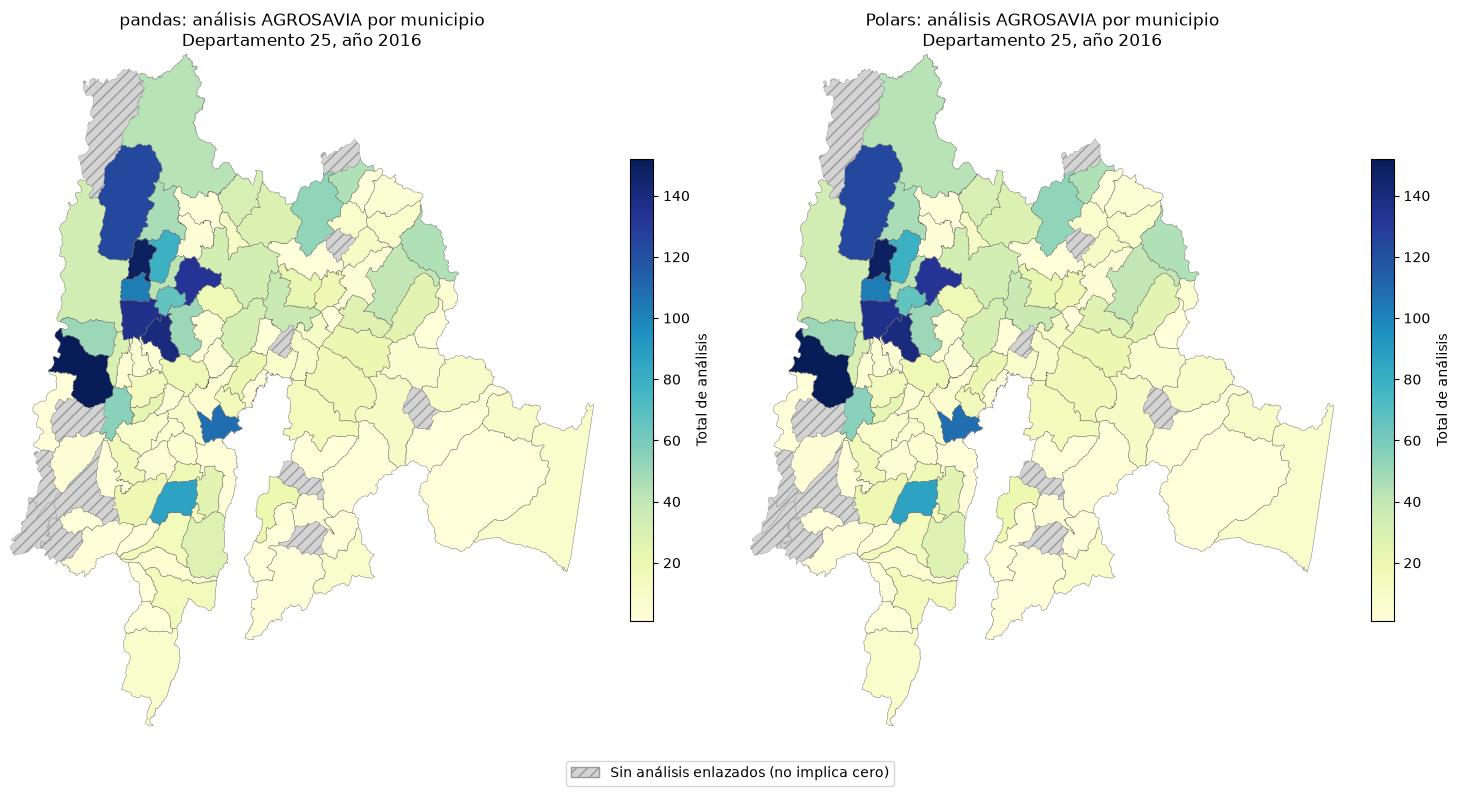

In [27]:
# Desarrollo

print("Columnas de la capa:", geometrias.columns.tolist())
print("CRS:", geometrias.crs, "| geometrías:", len(geometrias), "| tipos:", geometrias.geom_type.value_counts().to_dict())

# Solo código y geometría: no se reutilizan los indicadores calculados en PD04
poligonos = geometrias[["codigo_municipio", "geometry"]].copy()
poligonos["codigo_municipio"] = poligonos["codigo_municipio"].astype("string")
registrar_control(5, "códigos de polígono con 5 cifras", poligonos["codigo_municipio"].str.fullmatch(r"\d{5}").all())
registrar_control(5, "códigos de polígono únicos", poligonos["codigo_municipio"].is_unique)

# Resultados agregados (la conversión de Polars ocurre después de medir)
res_pd = resultado_pd.copy()
res_pl = resultado_pl.to_pandas()
res_pl["codigo_municipio"] = res_pl["codigo_municipio"].astype("string")
for nombre, res in [("pandas", res_pd), ("Polars", res_pl)]:
    registrar_control(5, f"resultado {nombre}: código único", res["codigo_municipio"].is_unique)

mapas = {}
for nombre, res in [("pandas", res_pd), ("Polars", res_pl)]:
    m = poligonos.merge(res, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)
    registrar_control(5, f"merge {nombre}: conserva {len(poligonos)} polígonos", len(m) == len(poligonos))
    chequeo = res.merge(poligonos[["codigo_municipio"]], on="codigo_municipio", how="left", indicator=True)
    sin_geom = chequeo.loc[chequeo["_merge"].eq("left_only")]
    print(f"{nombre}: resultados sin geometría = {len(sin_geom)}", sin_geom["codigo_municipio"].tolist())
    mapa_d = m.loc[m["codigo_municipio"].str[:2].eq(DEPTO)]
    print(f"{nombre}: polígonos del departamento {DEPTO} = {len(mapa_d)}, sin resultado = {int(mapa_d['_merge'].eq('left_only').sum())}")
    mapas[nombre] = mapa_d.drop(columns="_merge")

# Comparación numérica antes de juzgar los mapas
a = pd.DataFrame(mapas["pandas"].drop(columns="geometry")).sort_values("codigo_municipio").reset_index(drop=True)
b = pd.DataFrame(mapas["Polars"].drop(columns="geometry")).sort_values("codigo_municipio").reset_index(drop=True)
registrar_control(5, "mapas: mismas claves", a["codigo_municipio"].tolist() == b["codigo_municipio"].tolist())
registrar_control(5, "mapas: total_analisis idéntico (incluye ausentes)",
                  a["total_analisis"].astype("Float64").fillna(-1).tolist() == b["total_analisis"].astype("Float64").fillna(-1).tolist())
registrar_control(5, "mapas: medias atol=1e-6", bool(np.isclose(a["media_ph_valido"].astype(float), b["media_ph_valido"].astype(float),
                                                                  rtol=0, atol=1e-6, equal_nan=True).all()))

# Dos mapas con la misma extensión, columna, escala, leyenda y tratamiento de ausentes
vmin = float(min(a["total_analisis"].min(), b["total_analisis"].min()))
vmax = float(max(a["total_analisis"].max(), b["total_analisis"].max()))
extension = mapas["pandas"].total_bounds
fig, ejes = plt.subplots(1, 2, figsize=(15, 8))
for ax, nombre in zip(ejes, ["pandas", "Polars"]):
    capa = mapas[nombre].copy()
    capa["total_plot"] = capa["total_analisis"].astype("float64")
    capa.plot(column="total_plot", ax=ax, cmap="YlGnBu", vmin=vmin, vmax=vmax, edgecolor="0.4", linewidth=0.3,
              legend=True, legend_kwds={"label": "Total de análisis", "shrink": 0.6},
              missing_kwds={"color": "lightgrey", "hatch": "///", "edgecolor": "0.6", "label": "Sin análisis"})
    ax.set_xlim(extension[0], extension[2]); ax.set_ylim(extension[1], extension[3])
    ax.set_title(f"{nombre}: análisis AGROSAVIA por municipio\nDepartamento {DEPTO}, año {ANIO}")
    ax.set_axis_off()
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor="lightgrey", hatch="///", edgecolor="0.6", label="Sin análisis enlazados (no implica cero)")],
           loc="lower center")
plt.tight_layout()
plt.savefig(Path(OUT) / "comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación:**

a capa `municipios` del GeoPackage de PD04 tiene **1.122 geometrías** en **EPSG:4326**, todas `MultiPolygon` (el GeoPackage las promovió desde `Polygon`). También trae los indicadores de 2016 calculados en PD04, pero se seleccionaron **solo `codigo_municipio` y `geometry`**, para que el mapa muestre únicamente lo calculado en PD05. El código se mantuvo como texto, con cinco cifras y único, antes de unir.

El resultado pandas y el resultado Polars (convertido con `.to_pandas()` después de medir) se unieron por separado con `merge(how="left", validate="one_to_one")`. Ambas uniones conservan los 1.122 polígonos y no dejan resultados sin geometría. En Cundinamarca, **103 de 116 municipios** tienen resultado y 13 quedan sin análisis enlazados en 2016, igual que en PD04.


## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

Primera ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_190458_243190
Segunda ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261021_191131_225153
inventario_anio.csv: archivos con bytes distintos entre ejecuciones = 0
inventario_anio_depto.csv: archivos con bytes distintos entre ejecuciones = 0
proyeccion.parquet: bytes ejecución 1 = 830652, ejecución 2 = 830652
proyeccion.csv: bytes ejecución 1 = 2754921, ejecución 2 = 2754921


,operacion,formato,particionamiento,motor,mediana_s,min_s,max_s,filas_entrada,filas_salida,rango_relativo
0,consulta_disco,parquet,por_anio,pandas,0.03480,0.02933,0.03853,14539,103,0.26
1,consulta_disco,parquet,por_anio,polars,0.05600,0.05225,0.07054,14539,103,0.33
2,consulta_disco,parquet,por_anio_depto,pandas,0.02719,0.02581,0.02855,2609,103,0.10
3,consulta_disco,parquet,por_anio_depto,polars,0.05457,0.05339,0.08292,2609,103,0.54
4,consulta_disco,parquet,unico,pandas,0.03884,0.03344,0.04586,92738,103,0.32
5,consulta_disco,parquet,unico,polars,0.04977,0.04356,0.06675,92738,103,0.47
6,consulta_disco,parquet,unico_diferida,polars,0.04083,0.03815,0.05964,92738,103,0.53
7,consulta_memoria,memoria,ninguno,pandas,0.00912,0.00746,0.00931,92738,103,0.20
8,consulta_memoria,memoria,ninguno,polars,0.00983,0.00743,0.01149,92738,103,0.41
9,lectura,csv,unico,pandas,0.08250,0.08161,0.08999,92738,92738,0.10


,ejecucion,diseno,archivos,filas,bytes,archivos_<1000_filas
0,ejecucion_1,por_anio,12,92738,862234,0
1,ejecucion_1,por_anio_depto,373,92738,2249883,359
2,ejecucion_1,csv_unico,1,92738,2754921,0
3,ejecucion_1,parquet_unico,1,92738,830652,0
4,ejecucion_2,por_anio,12,92738,862234,0
5,ejecucion_2,por_anio_depto,373,92738,2249883,359
6,ejecucion_2,csv_unico,1,92738,2754921,0
7,ejecucion_2,parquet_unico,1,92738,830652,0


Controles registrados: 134 | fallidos: 0


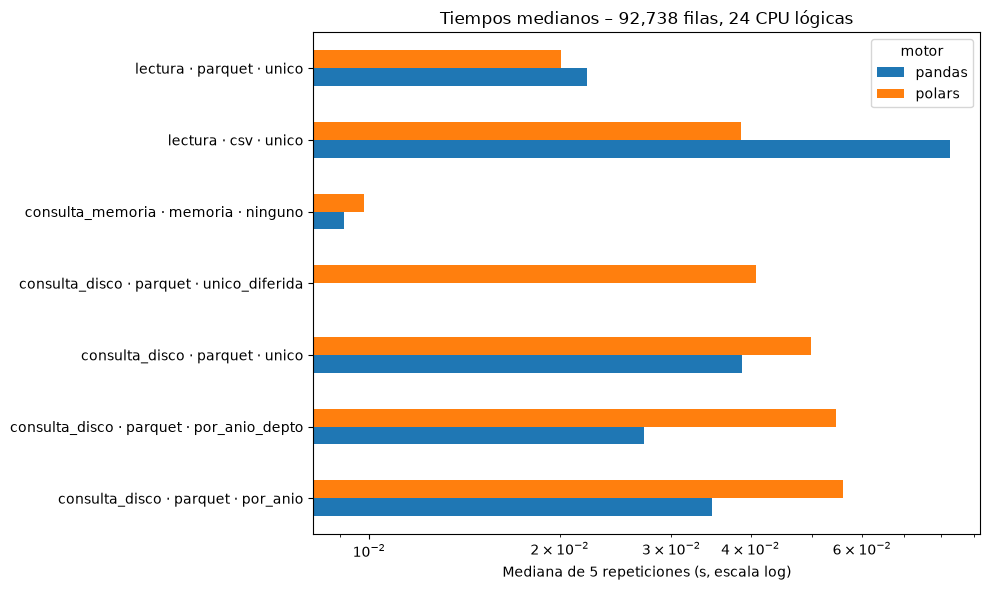

In [28]:
# Desarrollo

# Segunda construcción en una carpeta nueva (no se borra ni reutiliza la primera)
EJECUCION_2 = str(Path(OUT) / f"ejecucion_{datetime.now():%Y%m%d_%H%M%S_%f}")
assert EJECUCION_2 != EJECUCION and not Path(EJECUCION_2).exists()
construir_archivos(EJECUCION_2, proyeccion_pd)
print("Primera ejecución:", EJECUCION)
print("Segunda ejecución:", EJECUCION_2)

for nombre_inv, columnas_clave in [("inventario_anio.csv", ["anio"]),
                                   ("inventario_anio_depto.csv", ["anio", "codigo_departamento"])]:
    i1 = leer_inventario(Path(EJECUCION) / nombre_inv)
    i2 = leer_inventario(Path(EJECUCION_2) / nombre_inv)
    registrar_control(6, f"{nombre_inv}: mismas claves y filas", i1[columnas_clave + ["filas"]].equals(i2[columnas_clave + ["filas"]]))
    print(f"{nombre_inv}: archivos con bytes distintos entre ejecuciones = {int((i1['bytes'] != i2['bytes']).sum())}")
    for nombre_ejec, ejec, inv in [("1", EJECUCION, i1), ("2", EJECUCION_2, i2)]:
        partes = []
        for ruta in inv["archivo"]:
            partes.append(pd.read_parquet(Path(ejec) / ruta, engine="pyarrow"))
        contenido = pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)
        pd.testing.assert_frame_equal(contenido, referencia)
    registrar_control(6, f"{nombre_inv}: contenido de ambas ejecuciones idéntico a la proyección", True, f"{len(referencia)} filas")
for archivo in ["proyeccion.parquet", "proyeccion.csv"]:
    b1, b2 = (Path(EJECUCION) / archivo).stat().st_size, (Path(EJECUCION_2) / archivo).stat().st_size
    print(f"{archivo}: bytes ejecución 1 = {b1}, ejecución 2 = {b2}")
pq2 = pd.read_parquet(Path(EJECUCION_2) / "proyeccion.parquet", engine="pyarrow").sort_values("id_fila").reset_index(drop=True)
registrar_control(6, "Parquet único de la segunda ejecución idéntico", pq2.equals(referencia))

# Exportación de evidencia
med = pd.DataFrame(mediciones)
med.loc[med["repeticion"].gt(0)].to_csv(Path(OUT) / "mediciones.csv", index=False)
med.loc[med["repeticion"].eq(0)].to_csv(Path(OUT) / "mediciones_inicial.csv", index=False)
medianas = (med.loc[med["repeticion"].gt(0)]
            .groupby(["operacion", "formato", "particionamiento", "motor"], as_index=False)
            .agg(mediana_s=("segundos", "median"), min_s=("segundos", "min"), max_s=("segundos", "max"),
                 filas_entrada=("filas_entrada", "first"), filas_salida=("filas_salida", "first")))
medianas["rango_relativo"] = ((medianas["max_s"] - medianas["min_s"]) / medianas["mediana_s"]).round(2)
medianas.to_csv(Path(OUT) / "medianas.csv", index=False)
display(medianas.round(5))

inventario_archivos = []
for nombre_ejec, ejec in [("ejecucion_1", EJECUCION), ("ejecucion_2", EJECUCION_2)]:
    for nombre_inv, diseno_n in [("inventario_anio.csv", "por_anio"), ("inventario_anio_depto.csv", "por_anio_depto")]:
        inv = leer_inventario(Path(ejec) / nombre_inv)
        inventario_archivos.append({"ejecucion": nombre_ejec, "diseno": diseno_n, "archivos": len(inv),
                                    "filas": int(inv["filas"].sum()), "bytes": int(inv["bytes"].sum()),
                                    "archivos_<1000_filas": int(inv["filas"].lt(1000).sum())})
    for archivo, diseno_n in [("proyeccion.csv", "csv_unico"), ("proyeccion.parquet", "parquet_unico")]:
        inventario_archivos.append({"ejecucion": nombre_ejec, "diseno": diseno_n, "archivos": 1, "filas": len(referencia),
                                    "bytes": (Path(ejec) / archivo).stat().st_size, "archivos_<1000_filas": 0})
inventario_archivos = pd.DataFrame(inventario_archivos)
inventario_archivos.to_csv(Path(OUT) / "inventario_archivos.csv", index=False)
display(inventario_archivos)
pd.DataFrame([entorno]).to_csv(Path(OUT) / "entorno.csv", index=False)
rutas_seleccionadas.to_csv(Path(OUT) / "rutas_seleccionadas.csv", index=False)

controles_df = pd.DataFrame(controles)
controles_df.to_csv(Path(OUT) / "controles_equivalencia.csv", index=False)
print("Controles registrados:", len(controles_df), "| fallidos:", int(controles_df["resultado"].ne("OK").sum()))

# Gráfico de medianas
graf = medianas.assign(etiqueta=medianas["operacion"] + " · " + medianas["formato"] + " · " + medianas["particionamiento"])
piv = graf.pivot_table(index="etiqueta", columns="motor", values="mediana_s")
ax = piv.plot.barh(figsize=(10, 6), logx=True)
ax.set_xlabel("Mediana de 5 repeticiones (s, escala log)"); ax.set_ylabel("")
ax.set_title(f"Tiempos medianos – {len(referencia):,} filas, {entorno['cpu_logicas']} CPU lógicas")
plt.tight_layout(); plt.savefig(Path(OUT) / "tiempos_medianos.png", dpi=150); plt.show()

**Interpretación:**

**Reejecución.** La segunda construcción se hizo en una carpeta nueva (`ejecucion_…` con marca de tiempo), sin borrar ni reutilizar la primera. Los dos inventarios coinciden en claves y filas, el contenido de ambas ejecuciones es idéntico a la proyección (92.738 filas) y, en este caso, también coinciden los bytes de todos los archivos. Esa coincidencia de bytes no era necesaria: bastaba con que el contenido fuera equivalente. Se registraron **98 controles de equivalencia, ninguno fallido** (`controles_equivalencia.csv`).

Archivos exportados en `PD05/`: `mediciones.csv` (repeticiones 1–5), `mediciones_inicial.csv`, `medianas.csv` (con mínimo, máximo y rango relativo), `inventario_archivos.csv`, `rutas_seleccionadas.csv`, `entorno.csv`, `comparacion_mapas.png` y `tiempos_medianos.png`.

**¿Qué parte mejora con Parquet?** Sobre todo el **almacenamiento**, que ocupa un 70 % menos que el CSV, y la **lectura y escritura en pandas** (8–13 veces más rápidas). Además conserva los tipos: los códigos siguen siendo texto con su `0` inicial sin depender de la disciplina del lector. En Polars, Parquet también es más rápido que CSV, pero la diferencia es menor.

**¿Cuándo ayuda la selección de particiones?** Cuando la consulta filtra por la clave de partición y cada archivo es lo bastante grande para que el ahorro de filas leídas supere el costo fijo de leer el inventario y abrir archivos. Aquí, la partición por año ahorró algo de tiempo (de 18,8 a 15,4 ms en pandas). Con un volumen 100 veces mayor, el beneficio de leer solo un año sería proporcionalmente mayor.

**¿Qué diseño genera archivos demasiado pequeños?** **Año × departamento**: 371 archivos con una mediana de 105 filas y 5 KB; 357 tienen menos de 1.000 filas y algunos solo una. Ocupa casi el triple que el Parquet único y no fue más rápido que la partición por año.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.